# 📩 Detector de Spam en SMS — versión en **español** (Bi-GRU)

Entrena el mismo modelo del proyecto, pero con mensajes en español. Usa el dataset **SMS Spam Multilingual Collection** (Hugging Face), que contiene la colección SMS Spam original traducida a 20+ idiomas.

> ⚠️ **Importante:** las traducciones al español fueron hechas con un traductor automático (M2M100), no son mensajes escritos por personas. El modelo funcionará bien con español "estándar", pero puede fallar con jerga, abreviaturas o modismos locales.

**Resultado final:** `models/spam_gru_model_es.keras` + `reports/metrics_es.json`, que se copian a la carpeta del proyecto para que la app los use.

## 0. Configuración

In [18]:
!pip install -q langdetect
import os, random, json, re, unicodedata
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
MAX_TOKENS, SEQ_LEN, EMB_DIM, THRESHOLD = 8000, 50, 64, 0.5
os.makedirs("models", exist_ok=True); os.makedirs("reports", exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Selección y descripción del dataset

| | |
|---|---|
| **Nombre** | SMS Spam Multilingual Collection (`dbarbedillo/SMS_Spam_Multilingual_Collection_Dataset`, Hugging Face) |
| **Origen** | SMS Spam Collection (Almeida & Hidalgo, UCI), traducida a 20+ idiomas, entre ellos español |
| **Tarea** | Clasificación binaria de texto: `spam` vs `ham` (legítimo) |
| **Por qué es secuencial** | Un SMS es una secuencia de palabras: el orden y el contexto importan, ideal para una GRU |
| **Reto** | Clases desbalanceadas (~13 % spam) → se evalúa con precisión, recall, F1 y AUC, no solo accuracy |
| **Limitación** | El español es traducción automática, no mensajes escritos por personas |

### Descarga

In [19]:
CSV_PATH = "data-augmented.csv"
URL = "https://huggingface.co/datasets/dbarbedillo/SMS_Spam_Multilingual_Collection_Dataset/resolve/main/data-augmented.csv"
if not os.path.exists(CSV_PATH):
    !wget -q -O {CSV_PATH} "{URL}"
raw = pd.read_csv(CSV_PATH)
print("Filas:", len(raw), "| Columnas:", raw.columns.tolist())
raw.head(10)

Filas: 5572 | Columnas: ['Unnamed: 0', 'labels', 'text', 'text_hi', 'text_de', 'text_fr', 'text_es', 'text_zh', 'text_ar', 'text_bn', 'text_ru', 'text_pt', 'text_ja', 'text_id', 'text_ur', 'text_pa', 'text_jv', 'text_tr', 'text_ko', 'text_mr', 'text_uk', 'text_sv', 'text_no']


,Unnamed: 0,labels,text,text_hi,text_de,text_fr,text_es,text_zh,text_ar,text_bn,...,text_id,text_ur,text_pa,text_jv,text_tr,text_ko,text_mr,text_uk,text_sv,text_no
0,0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Ci...","Dakag बिंदु तक जाओ, पागल. केवल Bag Non महान विश्व cag में उपलब्ध है... वहाँ एक अधिक wa...","Gehen Sie bis jurong Punkt, verrückt.. Verfügbar nur in buggis n great world la e buff...","Allez jusqu'à Jurong point, fou.. Disponible seulement dans bugis n grand monde la e b...","Go until jurong point, crazy.. Available only in bugis n grand world la e buffet... Ci...","走到陪审点,疯狂.. 仅在 bugis n great world la e buffet... Cine there got amore wat...",الذهاب إلى نقطة الجورج، مجنون.. متوفر فقط في bugis n grand world la e buffet... Cine t...,যান যান যান যান যান যান যান যান যান যান যান যান যান যান যান যান যান যান যান যান যান যা...,...,"Pergi sampai jurong point, gila.. Tersedia hanya di bugis n besar dunia la e buffet......",جاؤ جب تک جورج پوائنٹ، پاگل.. دستیاب صرف میں bugis n عظیم world la e buffet... Cine th...,ਗਾਹਕ 'ਤੇ ਗਾਹਕ 'ਤੇ ਗਾਹਕ 'ਤੇ ਗਾਹਕ 'ਤੇ ਗਾਹਕ 'ਤੇ ਗਾਹਕ 'ਤੇ ਗਾਹਕ 'ਤੇ ਗਾਹਕ 'ਤੇ ਗਾਹਕ 'ਤੇ ਗਾਹਕ ...,"Ing titik jurong, crazy..Dapat ora ing bugis n grand world la e buffet... Cine there g...","Yürüyüş noktasına kadar gidin, çılgın.. Sadece bugis n büyük dünya la e buffet’te mevc...","조롱 포인트까지 가라, 미친.. 오직 bugis n great world la e buffet에서만 사용할 수 있습니다.","जॉर्ज बिंदुपर्यंत जा, पागल.. उपलब्ध फक्त bugis n महान world la e buffet... Cine there ...","Ідіть до пункту присяги, божевільний.. Доступно тільки в bugis n great world la e buff...","Go till jurong point, crazy.. Tillgänglig bara i bugis n great world la e buffet... Ci...","Gå til jurong point, gal.. Tilgjengelig bare i bugis n great world la e buffet... Cine..."
1,1,ham,Ok lar... Joking wif u oni...,ओके लामर.... if if uue पर.,Ok Lar... joking wif u oni...,J'ai fait une blague sur le wif u oni...,"Bueno, la broma, la broma...",哈哈哈哈哈哈哈哈哈哈哈哈哈哈哈哈哈,نعم نعم نعم نعم نعم نعم نعم...,হ্যাঁ হ্যাঁ হ্যাঁ হ্যাঁ হ্যাঁ হ্যাঁ হ্যাঁ হ্যাঁ...,...,"Awalnya, ia bergurau dengan Wif U...",ہا ہا ہا ہا ہا ہا ہا ہا ہا ہا ہا ہا ہا ہا ہا,OK lar... Joking wif u oni...,Lan lan lan lan lan lan lan lan lan lan lan lan...,Hayır hayır hayır hayır hayır hayır hayır,ᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏᄏ,"शंका आहोत, शंका आहोत, शंका आहोत...","Звичайно ж, це жартує про те, що...",Ok lar... Joking wif u oni...,Ok lar... Joking wif u oni...
2,2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...,Fktatatat 21 मई को प्राप्त करने के लिए मुफ्त प्रविष्टि में. पाठ FAO को 87121 में प्रवि...,Freier Eintritt in 2 a wkly comp zum Gewinn FA Cup Final tkts 21. Mai 2005. Text FA bi...,Entrée libre dans 2 a wkly comp pour gagner FA Cup final tkts 21 mai 2005. Texte FA à ...,Ingreso gratuito en 2 a wkly comp para ganar FA Cup final tkts 21st May 2005. Texto FA...,免费入场 2 a wkly comp 获胜 FA 杯决赛 tkts 2005年5月21日 文本 FA 到 87121 获取入场问题(std txt 率)T&C 申请 084...,إدخال مجاني في 2 a wkly comp للفوز FA Cup final tkts 21st مايو 2005. نص FA إلى 87121 ل...,বিনামূল্যে প্রবেশ 2 a wkly comp বিজয় FA কাপ ফাইনাল tkts 21st May 2005. Text FA to 871...,...,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...,مفت انٹرویو میں 2 a wkly comp جیتنے کے لئے FA کپ فائنل tkts 21st مئی 2005. متن FA to 8...,Free entry in 2 a wkly comp to win FA Cup final tkts 21st ਮਈ 2005. Text FA to 87121 to...,Free entry in 2 a wkly comp kanggo menang FA Cup final tkts 21st May 2005. Text FA kan...,Free entry in 2 a wkly comp to win FA Cup final tkts 21st Mayıs 2005. Text FA to 87121...,무료 입장 2 a wkly comp 승리 FA 컵 결승전 tkts 2005년 5월 21일 텍스트 FA to 87121 to receive entry que...,मुक्त प्रवेश 2 a wkly comp विजेता FA कप फाइनल tkts 21 मई 2005. Text FA to 87121 to rec...,Безкоштовний вхід у 2 а wkly comp виграти ФА Кубок фінал ткт 21 травня 2005. текст ФА ...,Fri entré i 2 a wkly comp för att vinna FA Cup final tkts 21 maj 2005. Text FA till 87...,Free entry in 2 a wkly c

## 2. Detección de columnas

No asumo los nombres de las columnas: el código busca la de texto (la de mensajes más largos), la de etiqueta (`spam`/`ham` o 0/1) y, si existe, una de idioma. **Si algo sale mal, fija los nombres a mano** en las variables `TEXT_COL`, `LABEL_COL`, `LANG_COL`.

In [20]:
TEXT_COL = LABEL_COL = LANG_COL = None   # <- rellena a mano si la detección falla, p. ej. TEXT_COL="text"

obj_cols = raw.select_dtypes(include=["object", "string"]).columns.tolist()
if TEXT_COL is None:
    TEXT_COL = max(obj_cols, key=lambda c: raw[c].astype(str).str.len().mean())
if LABEL_COL is None:
    ok = {"spam", "ham", "0", "1", "legitimate", "no spam", "not spam"}
    cands = [c for c in raw.columns if c != TEXT_COL and set(raw[c].dropna().astype(str).str.lower().unique()) <= ok]
    cands.sort(key=lambda c: raw[c].dtype not in ("object", "string"))   # prefiere la de texto (spam/ham)
    LABEL_COL = cands[0]
if LANG_COL is None:
    LANG_COL = next((c for c in raw.columns if "lang" in c.lower()), None)
print("TEXT_COL =", TEXT_COL, "| LABEL_COL =", LABEL_COL, "| LANG_COL =", LANG_COL)

lab = raw[LABEL_COL].astype(str).str.lower()
df = pd.DataFrame({"text": raw[TEXT_COL].astype(str), "y": lab.isin(["spam", "1"]).astype(int)})
if LANG_COL: df["lang"] = raw[LANG_COL].astype(str)
df = df.drop_duplicates(subset="text").reset_index(drop=True)
print("Filas únicas:", len(df)); print(df["y"].value_counts())

TEXT_COL = text_pa | LABEL_COL = labels | LANG_COL = None
Filas únicas: 4973
y
0    4369
1     604
Name: count, dtype: int64


## 3. Filtrar solo los mensajes en español

Si el CSV trae columna de idioma se usa; si no, se detecta el idioma con `langdetect` (puede tardar unos minutos). Se exige confianza ≥ 90 % para evitar mezclar idiomas.

In [21]:
from langdetect import detect_langs, DetectorFactory
DetectorFactory.seed = SEED

# Forzamos explícitamente la columna en español
TEXT_COL = "text_es"
print(f"Forzando TEXT_COL a '{TEXT_COL}' para procesar el texto en español.\n")

lab = raw[LABEL_COL].astype(str).str.lower()
df = pd.DataFrame({"text": raw[TEXT_COL].astype(str), "y": lab.isin(["spam", "1"]).astype(int)})
if LANG_COL: df["lang"] = raw[LANG_COL].astype(str)
df = df.drop_duplicates(subset="text").reset_index(drop=True)

# Tomamos una pequeña muestra de 100 filas para depurar
df_sample = df.sample(100, random_state=SEED).copy()

def is_es_debug(t):
    try:
        res = detect_langs(t)
        # Imprimimos los primeros diagnósticos para ver qué detecta el modelo en la muestra
        # print(f"Texto: {t[:40]}... -> Detectado: {res}")
        return any(l.lang == "es" and l.prob >= 0.90 for l in res)
    except Exception as e:
        # print(f"Error detectando: {e}")
        return False

print("Probando detección de idioma en una muestra de 100 mensajes...")
df_sample["es"] = df_sample["text"].apply(is_es_debug)
es_sample = df_sample[df_sample["es"]]

print(f"\n[Depuración] Mensajes procesados: {len(df_sample)}")
print(f"[Depuración] Mensajes identificados como español (confianza >= 90%): {len(es_sample)}")
if len(es_sample) > 0:
    display(es_sample.head(5))
else:
    print("Alerta: No se detectó ningún mensaje como español en esta muestra. Revisa el contenido de 'text_es'.")
    print("Muestra del contenido de 'text_es':")
    display(df_sample["text"].head(5))

Forzando TEXT_COL a 'text_es' para procesar el texto en español.

Probando detección de idioma en una muestra de 100 mensajes...

[Depuración] Mensajes procesados: 100
[Depuración] Mensajes identificados como español (confianza >= 90%): 79


,text,y,es
838,En el trabajo ahora. ir a tener en pocos minutos.,0,True
977,SiguienteSiguienteSiguienteSiguienteSiguienteSiguienteSiguienteSiguiente,0,True
2042,Su B4U voucher w/c 27/03 es MARSMS. Logue en www.B4Utele.com para el crédito de descue...,1,True
4637,"Bueno, no es como si realmente llamaste a alguien un punto.",0,True
2943,¡Feliz Año Nuevo!Abiola,0,True


## 4. EDA

label             ham   spam
length  count  3509.0  477.0
        mean     79.4  154.3
        std      58.9   35.9
        min       5.0   10.0
        25%      39.0  138.0
        50%      62.0  164.0
        75%     103.0  176.0
        max     751.0  298.0
n_words count  3509.0  477.0
        mean     14.6   25.5
        std      10.7    6.5
        min       1.0    2.0
        25%       7.0   23.0
        50%      11.0   27.0
        75%      19.0   30.0
        max     124.0   58.0

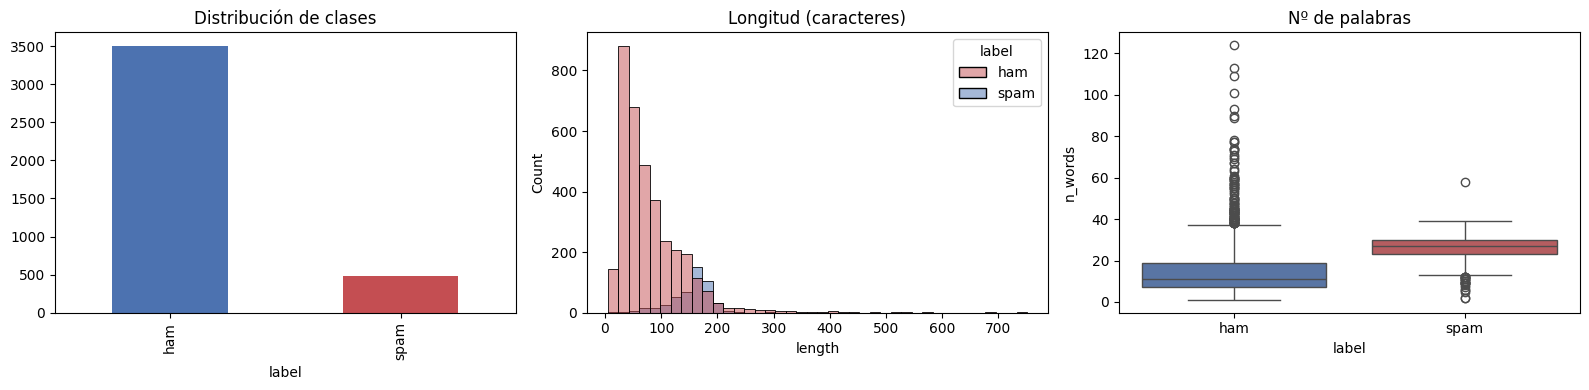

In [22]:
es["length"] = es["text"].str.len(); es["n_words"] = es["text"].str.split().str.len()
es["label"] = es["y"].map({0: "ham", 1: "spam"})
display(es.groupby("label")[["length", "n_words"]].describe().T.round(1))
pal = ["#4C72B0", "#C44E52"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
es["label"].value_counts().plot.bar(ax=ax[0], color=pal); ax[0].set_title("Distribución de clases")
sns.histplot(data=es, x="length", hue="label", bins=40, ax=ax[1], palette=pal[::-1]); ax[1].set_title("Longitud (caracteres)")
sns.boxplot(data=es, x="label", y="n_words", hue="label", legend=False, ax=ax[2], palette=pal); ax[2].set_title("Nº de palabras")
plt.tight_layout(); plt.show()

## 5. Limpieza (conserva tildes y ñ)

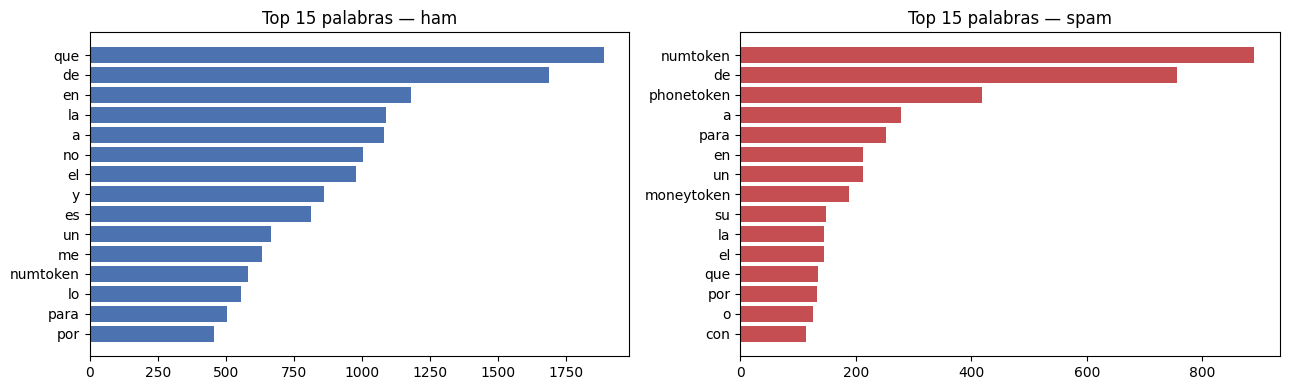

,text,clean
3227,Hay un buen fin de semana.,hay un buen fin de semana
810,Querido U've sido invitado a XCHAT. Este es nuestro último intento de contactar con U!...,querido u ve sido invitado a xchat este es nuestro último intento de contactar con u t...
3402,"Yo sigo viendo un extraño espanto y todos los ""woah"" y luego me siento que es realment...",yo sigo viendo un extraño espanto y todos los woah y luego me siento que es realmente ...
218,El 4 lo ha hecho un poco.,el numtoken lo ha hecho un poco
2221,Pls me envía el nombre correcto.,pls me envía el nombre correcto


In [23]:
URL_RE, EMAIL_RE = re.compile(r"(https?://\S+|www\.\S+)"), re.compile(r"\S+@\S+")
PHONE_RE, NUM_RE, MONEY_RE = re.compile(r"\b\d{5,}\b"), re.compile(r"\b\d+\b"), re.compile(r"[£$€]")

def clean_text_es(text: str) -> str:
    text = str(text).lower()
    text = URL_RE.sub(" urltoken ", text); text = EMAIL_RE.sub(" emailtoken ", text)
    text = MONEY_RE.sub(" moneytoken ", text); text = PHONE_RE.sub(" phonetoken ", text)
    text = NUM_RE.sub(" numtoken ", text)
    text = re.sub(r"[^a-záéíóúüñ\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

es["clean"] = es["text"].apply(clean_text_es)
es = es[es["clean"].str.len() > 0].reset_index(drop=True)

# Aseguramos la existencia de la columna 'label' mapeada desde 'y'
es["label"] = es["y"].map({0: "ham", 1: "spam"})

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
pal = ["#4C72B0", "#C44E52"]
for a, lab_, col in zip(ax, ["ham", "spam"], pal):
    cnt = Counter(" ".join(es[es.label == lab_]["clean"]).split())
    w, c = zip(*cnt.most_common(15)); a.barh(w[::-1], c[::-1], color=col); a.set_title(f"Top 15 palabras — {lab_}")
plt.tight_layout(); plt.show()
es[["text", "clean"]].sample(5, random_state=2)

## 6. División 70 / 15 / 15 (estratificada)

In [24]:
X_train, X_tmp, y_train, y_tmp = train_test_split(es["clean"], es["y"], test_size=0.30, stratify=es["y"], random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
raw_test = es.loc[X_test.index, "text"].values
X_train, X_val, X_test = X_train.values, X_val.values, X_test.values
y_train, y_val, y_test = y_train.values, y_val.values, y_test.values
for n, y in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(f"{n:5}: {len(y):5d} | % spam = {y.mean():.1%}")

Train:  2790 | % spam = 12.0%
Val  :   598 | % spam = 12.0%
Test :   598 | % spam = 11.9%


## 7. Modelo Bi-GRU y entrenamiento

In [25]:
vectorizer = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=SEQ_LEN)
vectorizer.adapt(X_train)
inputs = keras.Input(shape=(), dtype="string")
x = vectorizer(inputs)
x = layers.Embedding(MAX_TOKENS, EMB_DIM, mask_zero=True)(x)
x = layers.Bidirectional(layers.GRU(32))(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs, name="spam_bigru_es")
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")])
model.summary()

Model: "spam_bigru_es"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization… │ (None, 50)        │          0 │ input_layer_1[0]… │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 50, 64)    │    512,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 50)        │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 64)        │     18,816 │ embedding_1[0][0… │
│ (Bidirectional)     │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      2,080 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         33 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 532,929 (2.03 MB)

 Trainable params: 532,929 (2.03 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
88/88 - 26s - 291ms/step - accuracy: 0.6606 - loss: 0.5522 - precision: 0.2469 - recall: 0.8952 - val_accuracy: 0.9682 - val_loss: 0.1092 - val_precision: 0.8118 - val_recall: 0.9583
Epoch 2/30
88/88 - 16s - 183ms/step - accuracy: 0.9717 - loss: 0.1094 - precision: 0.8312 - recall: 0.9581 - val_accuracy: 0.9749 - val_loss: 0.1017 - val_precision: 0.8519 - val_recall: 0.9583
Epoch 3/30
88/88 - 6s - 64ms/step - accuracy: 0.9950 - loss: 0.0181 - precision: 0.9651 - recall: 0.9940 - val_accuracy: 0.9900 - val_loss: 0.0514 - val_precision: 0.9583 - val_recall: 0.9583
Epoch 4/30
88/88 - 6s - 72ms/step - accuracy: 0.9993 - loss: 0.0073 - precision: 0.9970 - recall: 0.9970 - val_accuracy: 0.9900 - val_loss: 0.0524 - val_precision: 0.9714 - val_recall: 0.9444
Epoch 5/30
88/88 - 11s - 120ms/step - accuracy: 1.0000 - loss: 0.0018 - precision: 1.0000 - recall: 1.0000 - val_accuracy: 0.9883 - val_loss: 0.0631 - val_precision: 0.9710 - val_recall: 0.9306
Epoch 6/30
88/88 - 5s - 58ms/step 

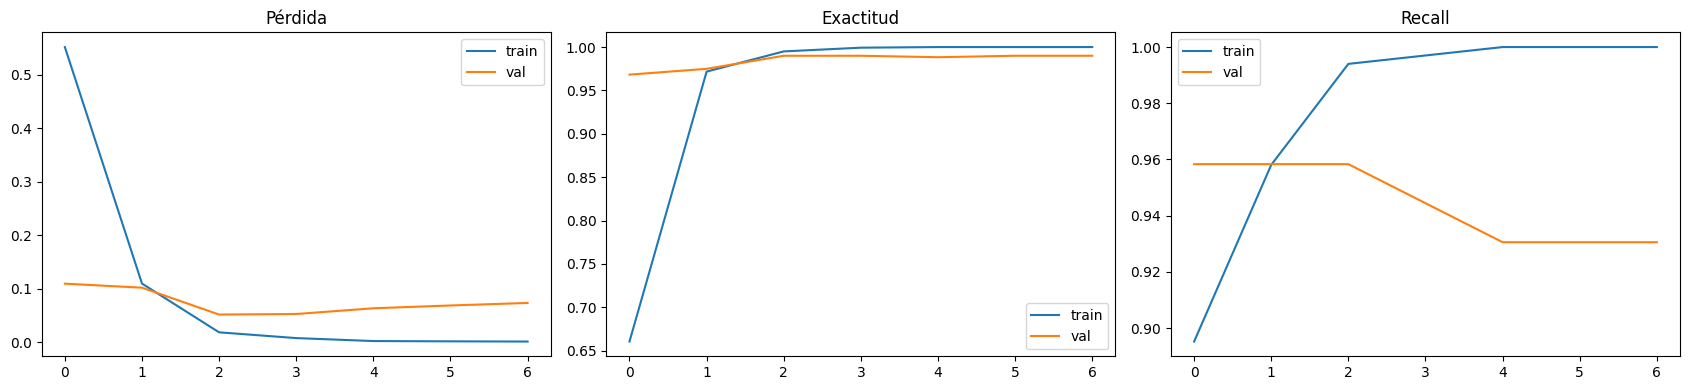

In [26]:
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}
def make_ds(X, y=None, shuffle=False):
    t = tf.constant(X, dtype=tf.string)
    ds = tf.data.Dataset.from_tensor_slices((t, y.astype("float32")) if y is not None else t)
    if shuffle: ds = ds.shuffle(len(X), seed=SEED)
    return ds.batch(32).prefetch(1)
es_cb = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
history = model.fit(make_ds(X_train, y_train, True), validation_data=make_ds(X_val, y_val),
                    epochs=30, class_weight=class_weight, callbacks=[es_cb], verbose=2)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, m, t in zip(ax, ["loss", "accuracy", "recall"], ["Pérdida", "Exactitud", "Recall"]):
    a.plot(history.history[m], label="train"); a.plot(history.history[f"val_{m}"], label="val"); a.set_title(t); a.legend()
plt.tight_layout(); plt.show()

## 8. Evaluación en test

accuracy     0.9716
precision    0.8649
recall       0.9014
f1           0.8828
roc_auc      0.9759

              precision    recall  f1-score   support

         ham       0.99      0.98      0.98       527
        spam       0.86      0.90      0.88        71

    accuracy                           0.97       598
   macro avg       0.93      0.94      0.93       598
weighted avg       0.97      0.97      0.97       598



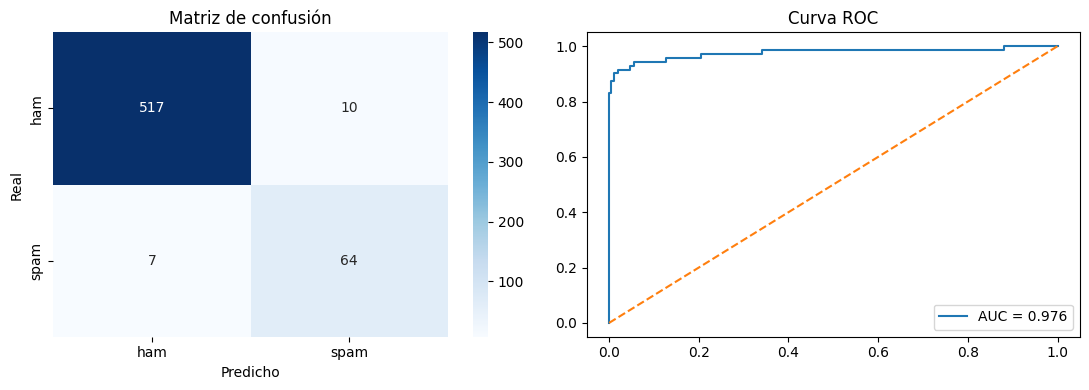

In [27]:
# Definimos la función auxiliar localmente para evitar el NameError si no se ejecutó la celda anterior
def make_ds(X, y=None, shuffle=False):
    t = tf.constant(X, dtype=tf.string)
    ds = tf.data.Dataset.from_tensor_slices((t, y.astype("float32")) if y is not None else t)
    if shuffle: ds = ds.shuffle(len(X), seed=SEED)
    return ds.batch(32).prefetch(1)

proba = model.predict(make_ds(X_test), verbose=0).ravel()
pred = (proba >= THRESHOLD).astype(int)
metrics = {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
           "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, proba)}
print(pd.Series(metrics).round(4).to_string()); print()
print(classification_report(y_test, pred, target_names=["ham", "spam"]))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax[0], xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
ax[0].set_title("Matriz de confusión"); ax[0].set_xlabel("Predicho"); ax[0].set_ylabel("Real")
fpr, tpr, _ = roc_curve(y_test, proba); ax[1].plot(fpr, tpr, label=f"AUC = {metrics['roc_auc']:.3f}"); ax[1].plot([0, 1], [0, 1], "--")
ax[1].set_title("Curva ROC"); ax[1].legend(); plt.tight_layout(); plt.show()

## 9. Predicciones de prueba

In [28]:
res = pd.DataFrame({"mensaje": raw_test, "real": np.where(y_test == 1, "spam", "ham"),
                    "prob_spam": proba.round(4), "predicho": np.where(pred == 1, "spam", "ham")})
res["correcto"] = np.where(res["real"] == res["predicho"], "✅", "❌")
muestra = pd.concat([res[res.real == "spam"].sample(8, random_state=SEED), res[res.real == "ham"].sample(8, random_state=SEED)])
pd.set_option("display.max_colwidth", 90); display(muestra.reset_index(drop=True))

nuevos = [
    "¡Felicidades! Has ganado un premio de 1000 euros. Llama al 09061701461 ahora para reclamarlo.",
    "Hola, ¿sigues queriendo almorzar mañana? Avísame a qué hora te viene bien.",
    "URGENTE: tu cuenta ha sido suspendida. Verifica tus datos en www.banco-seguro-login.com",
    "No olvides la reunión de mañana a las 10, llevaré los documentos.",
    "Entrada gratis a nuestro sorteo semanal. Envía GANA al 80086 para recibir tu tono.",
]
p = model.predict(tf.constant([clean_text_es(t) for t in nuevos]), verbose=0).ravel()
for t, pi in zip(nuevos, p): print(f"[{'SPAM' if pi >= THRESHOLD else 'HAM ':4}] P(spam)={pi:.3f} | {t}")

,mensaje,real,prob_spam,predicho,correcto
0,Gr8 nuevo servicio - chat de video de sexo en vivo en tu mob - ver las chicas más sexy...,spam,1.0000,spam,✅
1,dinero!!! usted es un ganador afortunado! 2 reclama su dinero de texto de premio 2 886...,spam,1.0000,spam,✅
2,Esta semana las ofertas de miembro de SavaMob están ahora disponibles. Sólo llame 0870...,spam,1.0000,spam,✅
3,"tddnewsletter@emc1.co.uk (Más juegos de TheDailyDraw) Querida Helen, Decenas de Juegos...",spam,0.9996,spam,✅
4,"Simplemente escriba la contraseña ""MIX"" a 85069 para verificar. Get Usher y Britney. F...",spam,1.0000,spam,✅
5,Usted tiene WON un dinero de 1.000 £ garantizado o un premio de 2.000 £.Para reclamar ...,spam,1.0000,spam,✅
6,"SMS SERVICES. para sus créditos de texto incluidos, pls goto www.comuk.net login= 3qxj...",spam,1.0000,spam,✅
7,1000 de las chicas muchos locales 2 u que r virgins 2 esto & r preparado 2 4fil ur cad...,spam,1.0000,spam,✅
8,¿No? 6 también no puede? entonces sólo cuántos errores?,ham,0.0008,ham,✅
9,"Ocho, te golpearé cuando obtenga un poco de dinero",ham,0.0020,ham,✅


[SPAM] P(spam)=1.000 | ¡Felicidades! Has ganado un premio de 1000 euros. Llama al 09061701461 ahora para reclamarlo.
[HAM ] P(spam)=0.000 | Hola, ¿sigues queriendo almorzar mañana? Avísame a qué hora te viene bien.
[SPAM] P(spam)=0.819 | URGENTE: tu cuenta ha sido suspendida. Verifica tus datos en www.banco-seguro-login.com
[HAM ] P(spam)=0.001 | No olvides la reunión de mañana a las 10, llevaré los documentos.
[SPAM] P(spam)=1.000 | Entrada gratis a nuestro sorteo semanal. Envía GANA al 80086 para recibir tu tono.


## 10. Guardado

In [29]:
model.save("models/spam_gru_model_es.keras")
json.dump({k: round(float(v), 4) for k, v in metrics.items()}, open("reports/metrics_es.json", "w"), indent=2)
reloaded = keras.models.load_model("models/spam_gru_model_es.keras")
print("Recarga idéntica:", np.allclose(p, reloaded.predict(tf.constant([clean_text_es(t) for t in nuevos]), verbose=0).ravel(), atol=1e-5))

# En Colab, descarga los dos archivos:
# from google.colab import files
# files.download("models/spam_gru_model_es.keras"); files.download("reports/metrics_es.json")

Recarga idéntica: True


## 11. Siguiente paso
Copia **`spam_gru_model_es.keras`** a `spam_project/models/` y **`metrics_es.json`** a `spam_project/reports/`. Al ejecutar `streamlit run app.py` aparecerá el selector **Español** en la barra lateral.